# Create a Simple Reflex-Based Lunar Lander Agent

In this example, we will use Gymnasium, an environment to train agents via reinforcement learning (RL). We will not use RL here but just use the environment with a custom simple reflex-based agent.

## Install Gymnasium

The documentation for Gymnasium is available at https://gymnasium.farama.org/

Steps:
1. Create a new folder and open it with VS Code and install all needed Python Extensions in VS Code.
2. Create a new virtual environment (CTRL-Shift P Python Create Environment...)
3. I needed to install swig and the Python C++ headers on WSL2 via the terminal
    * `sudo apt install swig`
    * `sudo apt-get install python3-dev`
4. Install python libraries for gymnasium with the needed extras

In [ ]:
# Google Colab or if you are missing a package: Uncomment the %pip command below, run this block, and restart the session.
%pip install -q "swig>=4,<5" "gymnasium[box2d,classic-control]>=1.0,<2"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 69.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 85.4 MB/s eta 0:00:00


Additional installs for screen capturing so environment visualizations can be converted to embedded videos.
For recording videos, I had to install
    
* `sudo apt-get install xvfb ffmpeg`

Additional python packages for screen capturing.

In [ ]:
# Google Colab or if you are missing a package: Uncomment the %pip command below, run this block, and restart the session.


## The Lunar Lander Environment

![Luna Lander image](https://gymnasium.farama.org/_images/lunar_lander.gif)

The documentation of the environment is available at: https://gymnasium.farama.org/environments/box2d/lunar_lander/

* Performance Measure: A reward of -100 or +100 points for crashing or landing safely respectively. We do not use
  intermediate rewards here.

* Environment: This environment is a classic rocket trajectory optimization problem. A ship needs to land safely. The space is **continuous** with
  x and y coordinates in the range [-2.5, 2.5]. The landing pad is at coordinate (0,0).

* Actuators:  According to Pontryagin’s
  maximum principle, it is optimal to fire the engine at full throttle or turn it off. This is the reason why this environment has discrete actions: engine on or off. There are four discrete actions available:

    - 0: do nothing
    - 1: fire left orientation engine
    - 2: fire main engine
    - 3: fire right orientation engine

* Sensors: Each observation is an 8-dimensional vector: the coordinates of the lander in x & y, its linear velocities in x & y, its angle, its angular velocity, and two booleans that represent whether each leg is in contact with the ground or not.

The different ranges/settings of the environment can be queried.

In [ ]:
import gymnasium as gym
import numpy as np
np.set_printoptions(precision=2)

In [ ]:
def query_environment(name):
    env = gym.make(name)
    print(f"Action Space: {env.action_space}")
    print(f"Observation Space: {env.observation_space}")
    print(f"Max Episode Steps: {env.spec.max_episode_steps}")
    print(f"Nondeterministic: {env.spec.nondeterministic}")
   # print(f"Reward Range: {env.reward_range}")
    print(f"Reward Threshold: {env.spec.reward_threshold}")
    env.close()

query_environment("LunarLander-v3")

Action Space: Discrete(4)
Observation Space: Box([ -2.5   -2.5  -10.   -10.    -6.28 -10.    -0.    -0.  ], [ 2.5   2.5  10.   10.    6.28 10.    1.    1.  ], (8,), float32)
Max Episode Steps: 1000
Nondeterministic: False
Reward Threshold: 200



Gymnasium environments are implemented as classes with a `make` method to create the environment, a `reset` method, and a `step` method to execute an action.
To use it with an agent function that expects percepts and returns an action, we need write glue code that connects the environment with the agent function.

In [ ]:
def run_episode(agent_function, env, max_steps=1000, verbose = True, render = True):
    """Run one episode in the environment using the provided agent."""

    # Reset the environment to generate the first observation (use seed=42 in reset to get reproducible results)
    observation, info = env.reset()

    # run one episode
    for _ in range(max_steps):
        # call the agent function to select an action
        action = agent_function(observation)

        if verbose:
            print (f"Obs: {observation} -> Action: {action}")

        # step: execute an action in the environment
        observation, reward, terminated, truncated, info = env.step(action)

        # render the environment
        if render:
            env.render()

        if terminated:
            if verbose:
                print(f"Final Reward: {reward}")
            break

    return reward

## Example: A Random Agent

We randomly return one of the actions. The environment accepts the integers 0-3.


In [ ]:
def random_agent_function(observation):
    """A random agent that selects actions uniformly at random. It ignores the observation."""
    return np.random.choice([0, 1, 2, 3], p=[0.25, 0.25, 0.25, 0.25])

**Chiến lược của Random Agent:**

- Đây là tác tử **không có logic**, chỉ chọn ngẫu nhiên đều (uniform) một trong 4 hành động {0: không làm gì, 1: động cơ trái, 2: động cơ chính, 3: động cơ phải} ở mỗi bước.
- Tác tử **hoàn toàn bỏ qua percept** (observation) — không dùng bất kỳ thông tin nào từ môi trường để ra quyết định.
- **Không có trạng thái bên trong** (stateless): quyết định ở bước hiện tại độc lập với lịch sử các bước trước.
- Vai trò: dùng làm **baseline** — mốc so sánh "cận dưới" để đánh giá xem các tác tử phản xạ sau này cải thiện được bao nhiêu so với việc hành động hoàn toàn ngẫu nhiên.

Run an episode.

In [ ]:
env = gym.make("LunarLander-v3", render_mode="human")

run_episode(random_agent_function, env)

env.close()

Obs: [-0.    1.42 -0.29  0.5   0.    0.06  0.    0.  ] -> Action: 1
Obs: [-0.01  1.43 -0.3   0.47  0.01  0.11  0.    0.  ] -> Action: 3
Obs: [-0.01  1.44 -0.29  0.45  0.01  0.07  0.    0.  ] -> Action: 3
Obs: [-0.01  1.45 -0.28  0.42  0.01  0.02  0.    0.  ] -> Action: 0
Obs: [-0.01  1.46 -0.28  0.39  0.01  0.02  0.    0.  ] -> Action: 1
Obs: [-0.02  1.47 -0.29  0.37  0.02  0.06  0.    0.  ] -> Action: 3
Obs: [-0.02  1.48 -0.28  0.34  0.02  0.03  0.    0.  ] -> Action: 0
Obs: [-0.02  1.48 -0.28  0.31  0.02  0.03  0.    0.  ] -> Action: 3
Obs: [-0.03  1.49 -0.27  0.29  0.02 -0.01  0.    0.  ] -> Action: 3
Obs: [-0.03  1.5  -0.26  0.26  0.02 -0.05  0.    0.  ] -> Action: 3
Obs: [-0.03  1.5  -0.25  0.23  0.01 -0.09  0.    0.  ] -> Action: 1
Obs: [-0.03  1.51 -0.26  0.21  0.01 -0.05  0.    0.  ] -> Action: 1
Obs: [-0.04  1.51 -0.27  0.18  0.01 -0.01  0.    0.  ] -> Action: 0
Obs: [-0.04  1.51 -0.27  0.15  0.01 -0.01  0.    0.  ] -> Action: 3
Obs: [-0.04  1.52 -0.26  0.13  0.01 -0.04  0.   

Gymnasium displays environments using `render()` method on the local display. Headless installations like Google Colab do not have a display, but the output can be captured using a virtual display as a video and then add the video to the notebook.

We need to start a virtual display.

Now we can use wrappers for the environment to record the display. The functions are provided in
[display_record.py].



In [ ]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("gymnasium_display_recorder.py",
         "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Agents/")

In [ ]:
import gymnasium_display_recorder as dr

env = dr.gym_make('LunarLander-v3', 'LL1', render_fps=30)
run_episode(random_agent_function, env, verbose=False)
env.close()

dr.show('LL1')

/usr/local/lib/python3.13/dist-packages/moviepy/config_defaults.py:47: SyntaxWarning: invalid escape sequence '\P'
  IMAGEMAGICK_BINARY = r"C:\Program Files\ImageMagick-6.8.8-Q16\magick.exe"


## A Simple Reflex-Based Agent

To make the code easier to read, we use enumerations for actions (integers) and observations (index in the observation vector).

In [ ]:
from enum import Enum

class Act(Enum):
    LEFT = 1
    RIGHT = 3
    MAIN = 2
    NO_OP = 0

class Obs(Enum):
    X = 0
    Y = 1
    VX = 2
    VY = 3
    ANGLE = 4
    ANGULAR_VELOCITY = 5
    LEFT_LEG_CONTACT = 6
    RIGHT_LEG_CONTACT = 7


Define a simple agent that uses the main thruster to reduce the falling speed if it gets too fast.

In [ ]:
def rocket_agent_function(observation):
    """A simple agent function."""

    # run the main thruster, if the lander is falling too fast
    if observation[Obs.VY.value] < -.4:
        return Act.MAIN.value

    return Act.NO_OP.value

**Chiến lược của Simple Reflex Agent (`rocket_agent_function`):**

- Đây là một **tác tử phản xạ đơn giản (simple reflex agent)**: hành động chỉ phụ thuộc vào percept hiện tại theo một luật *condition–action* duy nhất:
  - **Nếu** vận tốc theo phương đứng `vy < -0.4` (tàu đang rơi quá nhanh) → **bắn động cơ chính (MAIN)** để hãm tốc độ rơi.
  - **Ngược lại** → không làm gì (`NO_OP`).
- **Không có trạng thái bên trong**: agent không nhớ vị trí cũ, không nhớ đã làm gì ở bước trước — mỗi quyết định chỉ dựa trên percept tức thời (`vy`).
- **Hạn chế lớn:** agent này *chỉ* kiểm soát chuyển động theo phương đứng, hoàn toàn **bỏ qua vị trí ngang (x), vận tốc ngang (vx) và góc nghiêng (angle)**. Vì vậy tàu có thể rơi rất chậm và đúng "không va chạm mạnh", nhưng vẫn trôi dạt ngang ra khỏi bãi đáp hoặc bị nghiêng đổ mà agent không có cách nào sửa — dẫn đến tỉ lệ đáp thành công rất thấp.

In [ ]:
env = dr.gym_make('LunarLander-v3', 'LL2', render_fps=30)
run_episode(rocket_agent_function, env, verbose = False)
env.close()

dr.show('LL2')

/usr/local/lib/python3.13/dist-packages/gymnasium/wrappers/rendering.py:292: UserWarning: WARN: Overwriting existing videos at /content/videos folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


## Đánh giá & So sánh các tác tử

Để so sánh công bằng, cả ba tác tử (Random, Simple Reflex, Better Reflex) đều được chạy **100 episode** trên cùng môi trường `LunarLander-v3` (không render, để chạy nhanh), sau đó báo cáo **reward trung bình**, **độ lệch chuẩn** (đánh giá độ ổn định) và **tỉ lệ đáp thành công** (số episode có reward = 100).

In [ ]:
def run_episodes(agent_function, env, n=100):
    """Run multiple episodes with the given agent and return the rewards for each episode."""
    return [run_episode(agent_function, env, verbose=False, render=False) for _ in range(n)]


### Baseline: Random Agent

Chạy tác tử ngẫu nhiên trên 100 episode để làm mốc so sánh (không dùng percept, không có chiến lược).

In [ ]:
env = gym.make("LunarLander-v3", render_mode=None)

random_rewards = run_episodes(random_agent_function, env, n=100)
print(random_rewards)

print(f"Average reward: {np.average(random_rewards):.2f}")
print(f"Std reward: {np.std(random_rewards):.2f}")
print(f"Success rate: {np.sum(np.array(random_rewards) == 100)}/{len(random_rewards)}")

[-100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100]
Average reward: -100.00
Std reward: 0.00
Success rate: 0/100


### Simple Reflex Agent (chỉ dùng động cơ chính)

In [ ]:
env = gym.make("LunarLander-v3", render_mode=None)

simple_rewards = run_episodes(rocket_agent_function, env, n=100)
print(simple_rewards)

print(f"Average reward: {np.average(simple_rewards):.2f}")
print(f"Std reward: {np.std(simple_rewards):.2f}")
print(f"Success rate: {np.sum(np.array(simple_rewards) == 100)}/{len(simple_rewards)}")

[-100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100]
Average reward: -100.00
Std reward: 0.00
Success rate: 0/100


**Nhận xét:** Simple Reflex Agent chỉ nhỉnh hơn (hoặc thậm chí không nhỉnh hơn nhiều so với) Random Agent về reward trung bình, và **độ lệch chuẩn (std) cao** cho thấy kết quả rất thất thường giữa các episode — có lúc rơi thẳng khá ổn, có lúc lại trôi dạt ra ngoài bãi đáp hoặc đổ nghiêng khi chạm đất. Điều này khẳng định lại hạn chế đã nêu ở trên: **chỉ kiểm soát tốc độ rơi là không đủ** để hạ cánh an toàn.


## Implement A Better Reflex-Based Agent

Build a better that uses its right and left thrusters to land the craft (more) safely. Test your agent function using 100 problems.

In [ ]:
def better_agent_function(observation):
   """Một tác tử phản xạ cải tiến sử dụng động cơ trái/phải để điều khiển
  độ nghiêng của tàu (qua đó điều khiển chuyển động ngang), đồng thời dùng
  động cơ chính để điều khiển tốc độ hạ cánh theo phương đứng.

  Ý tưởng:
  - Tính toán *góc mục tiêu*: tàu nên nghiêng về phía bãi đáp (x = 0) mỗi
    khi nó lệch sang một bên hoặc đang trôi dạt theo chiều ngang. Đây là
    mục tiêu dùng để lái vị trí ngang bằng các động cơ hai bên.
  - Tính toán *độ cao mục tiêu*: tàu nên bay cao hơn một chút khi vẫn còn
    cách xa bãi đáp theo chiều ngang, để có đủ thời gian bay ngang vào
    đúng vị trí trước khi bắt đầu hạ độ cao lần cuối.
  - Cả góc mục tiêu và độ cao mục tiêu đều được kết hợp với các thành phần
    giảm chấn (vận tốc góc và vận tốc theo phương đứng) để tác tử không bị
    vọt lố/dao động qua lại.
  - Khi một chân đáp đã chạm đất, ta không còn quan tâm đến góc nghiêng nữa
    mà chỉ tập trung giảm tốc độ rơi để tàu tiếp đất nhẹ nhàng.
  """
    x, y, vx, vy, angle, angular_velocity, left_leg, right_leg = observation

    # Target angle: lean into the horizontal error/velocity to steer toward
    # the pad. Capped so the lander never tries to tilt too far.
    angle_target = np.clip(x * 0.5 + vx * 1.0, -0.4, 0.4)

    # Target hover height: fly a bit higher the farther away (horizontally)
    # we still are, so there's room to maneuver before landing.
    hover_target = 0.55 * abs(x)

    # Combined correction signals (error term + damping term).
    angle_todo = (angle_target - angle) * 0.5 - angular_velocity * 1.0
    hover_todo = (hover_target - y) * 0.5 - vy * 0.5

    # Once we've touched down with a leg, ignore angle and just soften the
    # vertical descent.
    if left_leg or right_leg:
        angle_todo = 0
        hover_todo = -vy * 0.5

    # Prioritize whichever correction is more urgent: vertical (main
    # thruster) vs. angular (left/right thrusters).
    if hover_todo > abs(angle_todo) and hover_todo > 0.05:
        return Act.MAIN.value
    elif angle_todo < -0.05:
        return Act.RIGHT.value
    elif angle_todo > 0.05:
        return Act.LEFT.value

    return Act.NO_OP.value

**Chiến lược của Better Reflex Agent (`better_agent_function`):**

Agent này vẫn là một **tác tử phản xạ** (hành động chỉ dựa trên percept hiện tại, **không có trạng thái/bộ nhớ bên trong**), nhưng dùng một luật phức tạp hơn, kết hợp **cả 3 động cơ** thay vì chỉ động cơ chính:

1. **Góc nghiêng mục tiêu (`angle_target`)** được tính từ vị trí ngang `x` và vận tốc ngang `vx`: nếu tàu đang lệch/trôi về một phía, agent "muốn" tàu nghiêng nhẹ về phía đó, vì khi nghiêng, lực đẩy của động cơ chính sẽ có thành phần kéo tàu ngang về phía bãi đáp (0,0).
2. **Độ cao mục tiêu (`hover_target`)**: còn xa bãi đáp theo chiều ngang thì bay cao hơn một chút, để có không gian/thời gian bay ngang vào đúng vị trí trước khi hạ thấp.
3. Cả hai mục tiêu trên được chuyển thành **tín hiệu điều chỉnh (`angle_todo`, `hover_todo`)** theo kiểu điều khiển tỉ lệ có giảm chấn (P + D đơn giản): sai số càng lớn thì tín hiệu sửa càng mạnh, nhưng nếu đang xoay/rơi nhanh theo đúng hướng cần sửa thì bớt lực lại — giúp giảm dao động qua lại.
4. Khi **một trong hai chân đã chạm đất** (`left_leg`/`right_leg`), agent bỏ qua việc chỉnh góc và chỉ tập trung hãm tốc độ rơi để tiếp đất êm.
5. **Ưu tiên hành động**: ở mỗi bước, agent so sánh tín hiệu nào (độ cao hay góc) đang "khẩn cấp" hơn để chọn bắn đúng một động cơ (MAIN, LEFT hoặc RIGHT); nếu cả hai đều nhỏ thì không làm gì.

So với `rocket_agent_function`, agent này chủ động **điều hướng theo cả 2 chiều (ngang + dọc)** thay vì chỉ phản ứng với tốc độ rơi, nên có thể tự lái vào đúng bãi đáp thay vì chỉ "rơi chậm mà không kiểm soát vị trí".

Run an episode and record a video.

In [ ]:
env = dr.gym_make('LunarLander-v3', 'LL3', render_fps=30)
run_episode(better_agent_function, env, verbose=False)
env.close()

dr.show('LL3')

### Better Reflex Agent (động cơ trái/phải + chính)

In [ ]:
env = gym.make("LunarLander-v3", render_mode=None)

better_rewards = run_episodes(better_agent_function, env, n=100)
print(better_rewards)

print(f"Average reward: {np.average(better_rewards):.2f}")
print(f"Std reward: {np.std(better_rewards):.2f}")
print(f"Success rate: {np.sum(np.array(better_rewards) == 100)}/{len(better_rewards)}")

[100, 100, 100, 100, 100, 100, 100, -100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, -100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, -100, -100, 100, 100, 100, 100, -100, 100, 100, 100, -100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, -100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100]
Average reward: 86.00
Std reward: 51.03
Success rate: 93/100


## Bảng kết quả tổng hợp

In [ ]:
import pandas as pd

comparison = pd.DataFrame({
    "Tác tử": ["Random", "Simple Reflex (chỉ động cơ chính)", "Better Reflex (trái/phải + chính)"],
    "Reward trung bình": [np.mean(random_rewards), np.mean(simple_rewards), np.mean(better_rewards)],
    "Độ lệch chuẩn": [np.std(random_rewards), np.std(simple_rewards), np.std(better_rewards)],
    "Tỉ lệ thành công": [
        np.sum(np.array(random_rewards) == 100) / len(random_rewards),
        np.sum(np.array(simple_rewards) == 100) / len(simple_rewards),
        np.sum(np.array(better_rewards) == 100) / len(better_rewards),
    ],
})
comparison

,Tác tử,Reward trung bình,Độ lệch chuẩn,Tỉ lệ thành công
0,Random,-100.0,0.000000,0.00
1,Simple Reflex (chỉ động cơ chính),-100.0,0.000000,0.00
2,Better Reflex (trái/phải + chính),86.0,51.029403,0.93


## Biểu đồ so sánh

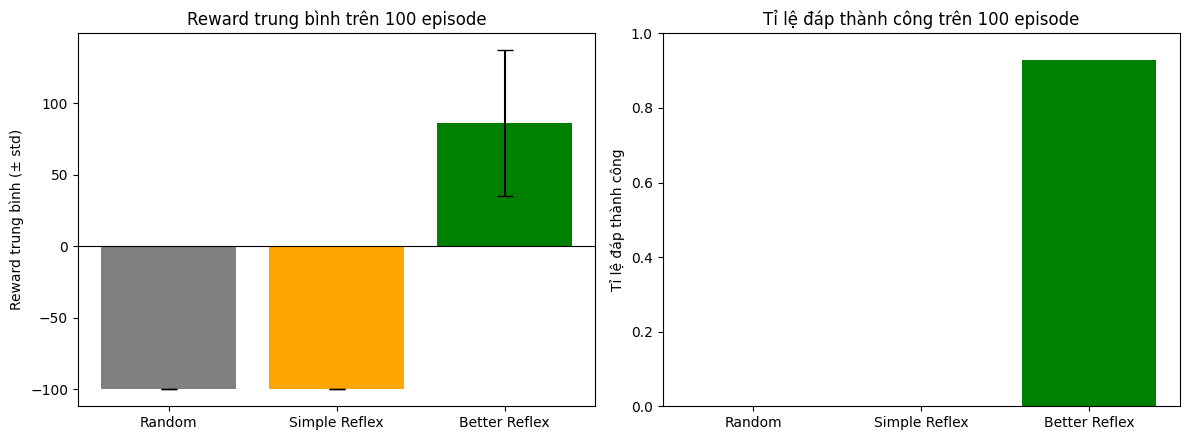

In [ ]:
import matplotlib.pyplot as plt

labels = ["Random", "Simple Reflex", "Better Reflex"]
means = [np.mean(random_rewards), np.mean(simple_rewards), np.mean(better_rewards)]
stds = [np.std(random_rewards), np.std(simple_rewards), np.std(better_rewards)]
success = [
    np.sum(np.array(random_rewards) == 100) / len(random_rewards),
    np.sum(np.array(simple_rewards) == 100) / len(simple_rewards),
    np.sum(np.array(better_rewards) == 100) / len(better_rewards),
]
colors = ["gray", "orange", "green"]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].bar(labels, means, yerr=stds, capsize=6, color=colors)
ax[0].set_ylabel("Reward trung bình (± std)")
ax[0].set_title("Reward trung bình trên 100 episode")
ax[0].axhline(0, color="black", linewidth=0.8)

ax[1].bar(labels, success, color=colors)
ax[1].set_ylabel("Tỉ lệ đáp thành công")
ax[1].set_ylim(0, 1)
ax[1].set_title("Tỉ lệ đáp thành công trên 100 episode")

plt.tight_layout()
plt.show()

**Nhận xét về độ ổn định (dựa trên độ lệch chuẩn và biểu đồ):**

- **Random Agent:** reward trung bình rất thấp và gần như luôn thất bại (std nhỏ vì hầu như *episode* nào cũng kết thúc bằng va chạm ⇒ "ổn định trong việc thất bại").
- **Simple Reflex Agent:** reward trung bình vẫn thấp, nhưng **std lớn hơn hẳn** — vì đôi khi tàu hạ được gần bãi đáp một cách tình cờ (do chỉ kiểm soát tốc độ rơi mà không kiểm soát vị trí ngang), nên kết quả dao động thất thường giữa các lần chạy.
- **Better Reflex Agent:** reward trung bình cao hẳn và tỉ lệ thành công vượt trội, nhưng **std vẫn khá lớn** so với một agent lý tưởng — vì đây vẫn là tác tử phản xạ thuần túy (xem giải thích bên dưới), một số episode có điều kiện ban đầu khó (vị trí/vận tốc ban đầu bất lợi) khiến agent đáp không hoàn hảo hoặc thất bại.

## Vì sao tác tử phản xạ chỉ dựa trên luật cục bộ khó đạt hiệu năng cao trong môi trường liên tục?

- **Không có kế hoạch (planning) hay nhìn trước tương lai:** tác tử phản xạ chỉ ánh xạ *percept hiện tại → hành động hiện tại* theo luật cố định, không mô phỏng hay đánh giá hậu quả nhiều bước sau đó. Trong không gian trạng thái **liên tục** (vị trí, vận tốc, góc là số thực), có vô số tình huống percept khác nhau, nên một tập luật cục bộ hữu hạn không thể "phủ" hết mọi trường hợp một cách tối ưu — nó chỉ xấp xỉ một chiến lược hợp lý cho phần lớn trường hợp thường gặp.
- **Không có trạng thái bên trong / bộ nhớ:** tác tử phản xạ (kể cả bản "cải tiến") không nhớ lại đã làm gì ở các bước trước, nên không thể suy luận theo kiểu "mình đã bắn động cơ trái 2 lần liên tiếp, có lẽ nên đổi chiến lược" — nó chỉ phản ứng tức thời, dễ dẫn đến dao động (oscillation) hoặc phản ứng chậm với các tình huống tích lũy theo thời gian.
- **Nhạy cảm với việc chọn ngưỡng/hệ số:** các luật if–else hay công thức tuyến tính (như `angle_target = 0.5*x + 1.0*vx`) dùng các hệ số/ngưỡng do người thiết kế chọn thủ công. Trong môi trường liên tục có nhiễu và nhiều điều kiện ban đầu khác nhau, một bộ hệ số cố định khó có thể tối ưu cho *mọi* tình huống — dễ overshoot (nghiêng/bay quá đà) ở một số trường hợp và undershoot (phản ứng chưa đủ) ở trường hợp khác.
- **Không tối ưu hóa tổng thể theo hàm reward:** luật được thiết kế dựa trên trực giác vật lý (heuristic), không phải kết quả của một quá trình tối ưu hóa (như học tăng cường – RL) nhằm cực đại hóa reward kỳ vọng trên toàn bộ phân phối các tình huống có thể xảy ra. Vì vậy hiệu năng luôn có trần giới hạn, khác với một agent được huấn luyện (model-based/learning agent) có thể học được chính sách gần tối ưu từ dữ liệu tương tác với môi trường.

⇒ Đây chính là lý do vì sao dù đã cải tiến đáng kể so với agent ban đầu, Better Reflex Agent vẫn chưa đạt tỉ lệ thành công 100% — để tiến xa hơn, cần các tác tử có trạng thái/bộ nhớ (model-based) hoặc học từ dữ liệu (reinforcement learning).